In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "examples/diffusion/config.py").is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
from IPython.display import display

from examples.diffusion.config import RESULT_DIR
from examples.diffusion.analysis.comparison import (
    run_all_comparisons,
)
from examples.diffusion.analysis.plot import (
    has_dataset_type,
    load_runs,
    plot_gold_pmp_overview,
    plot_metric_grid,
    summarize_runs,
)


In [2]:
RESULT_ROOT = RESULT_DIR
OUTPUT_ROOT = RESULT_ROOT / "plots" / "n384" / "s4D"

SUMMARY_MULTIPLIERS = (4,)
DATASET_TYPE = "both"  # "both", "simulated", or "empirical"

# Existing comparison CSVs are already complete, so keep this False for normal plotting.
BUILD_COMPARISONS = False
OVERWRITE_COMPARISONS = False
CONVERGENCE_POLICY = "available"

LOESS_FRAC = 1  # one pooled fit across simulated + empirical when DATASET_TYPE="both"
LOESS_SPACE = "symlog"
DPI = 220


In [3]:
if BUILD_COMPARISONS:
    run_all_comparisons(
        summary_multipliers=SUMMARY_MULTIPLIERS,
        scoring_rules=(),
        splits=("simulated", "empirical"),
        result_dir=RESULT_ROOT,
        convergence_policy=CONVERGENCE_POLICY,
        allow_missing_empirical=False,
        overwrite=OVERWRITE_COMPARISONS,
    )


## Load S=4D comparison table

In [4]:
indirect_runs = load_runs(
    "indirect",
    summary_multipliers=SUMMARY_MULTIPLIERS,
    result_dir=RESULT_ROOT,
)
display(summarize_runs(indirect_runs))


run,method,rows,datasets,simulated,empirical,summary_multiplier,scoring_rule
S=4D,indirect,544,136,119,17,4,


## S=4D: posterior MMD vs diagnostic score

Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/diffusion/results/plots/n384/s4D/indirect/both/posterior_mmd_4x4.png
Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/diffusion/results/plots/n384/s4D/indirect/both/posterior_mmd_4x4.pdf


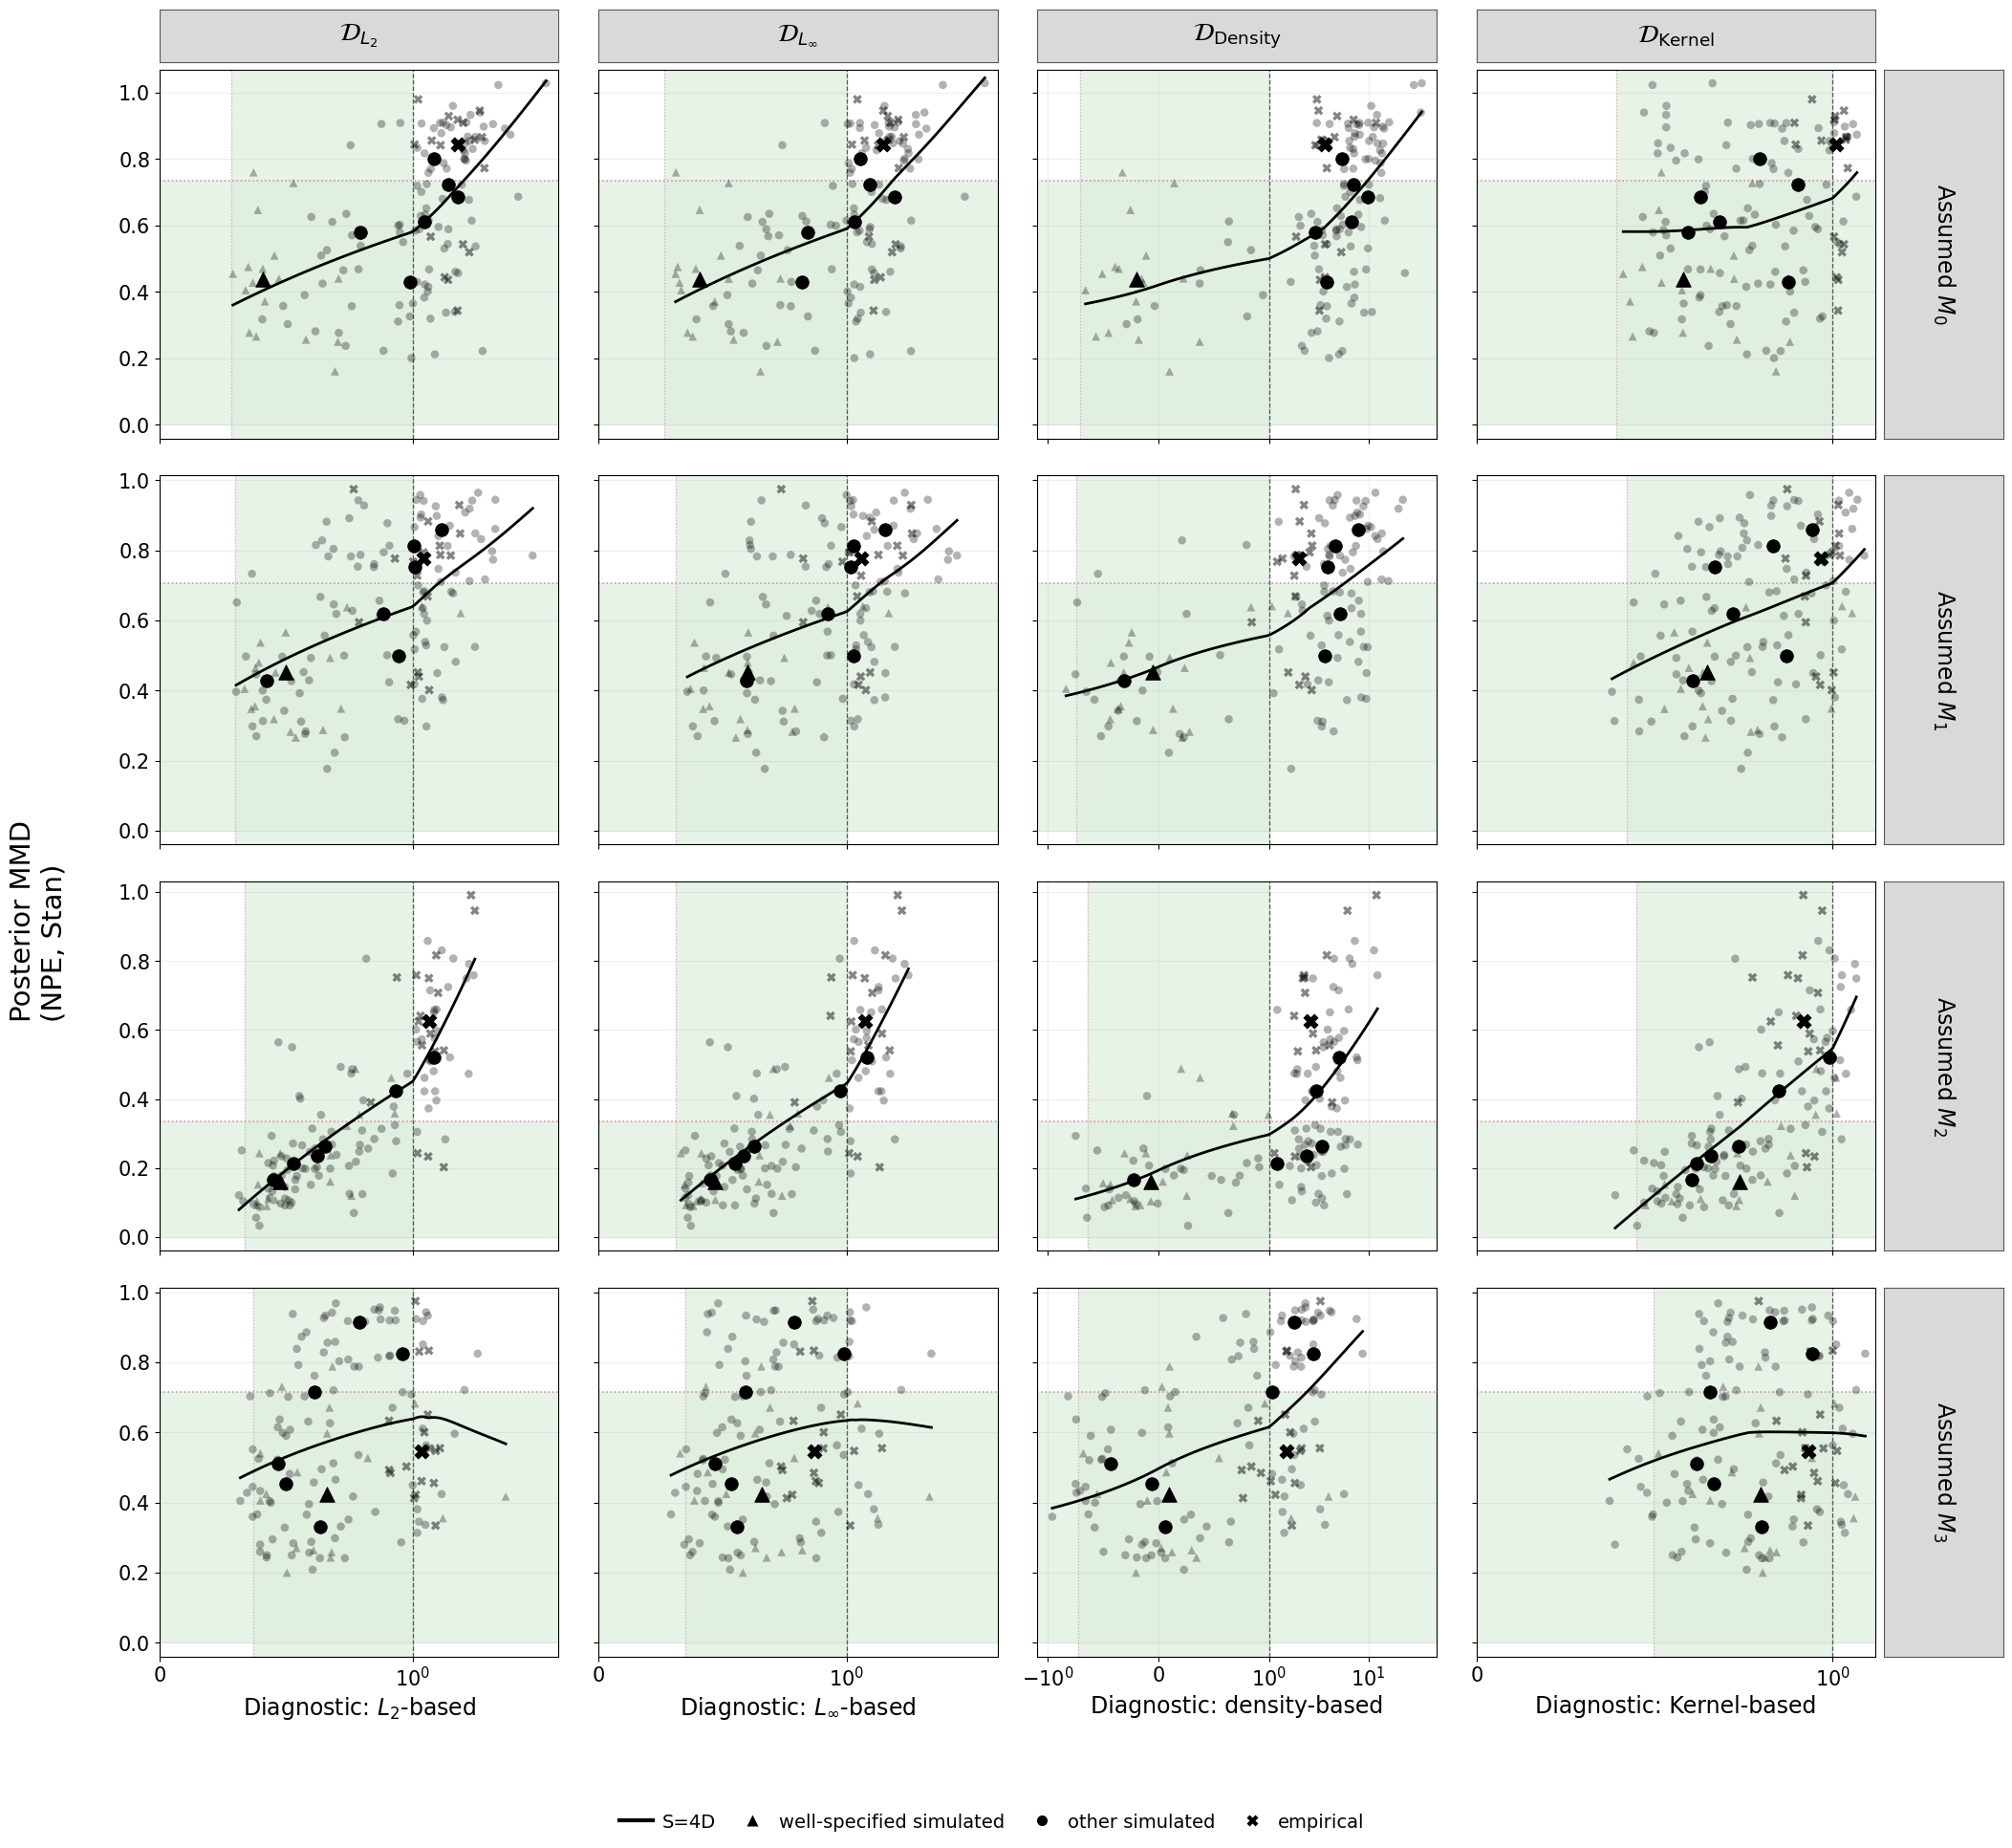

In [5]:
fig_mmd, axes_mmd = plot_metric_grid(
    indirect_runs,
    "posterior_mmd",
    dataset_type=DATASET_TYPE,
    output=OUTPUT_ROOT / "indirect" / DATASET_TYPE / "posterior_mmd_4x4",
    loess_frac=LOESS_FRAC,
    loess_space=LOESS_SPACE,
    point_color="black",
    loess_color="black",
    dpi=DPI,
)
plt.show()


## S=4D: log marginal-likelihood error vs diagnostic score

Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/diffusion/results/plots/n384/s4D/indirect/both/logml_error_4x4.png
Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/diffusion/results/plots/n384/s4D/indirect/both/logml_error_4x4.pdf


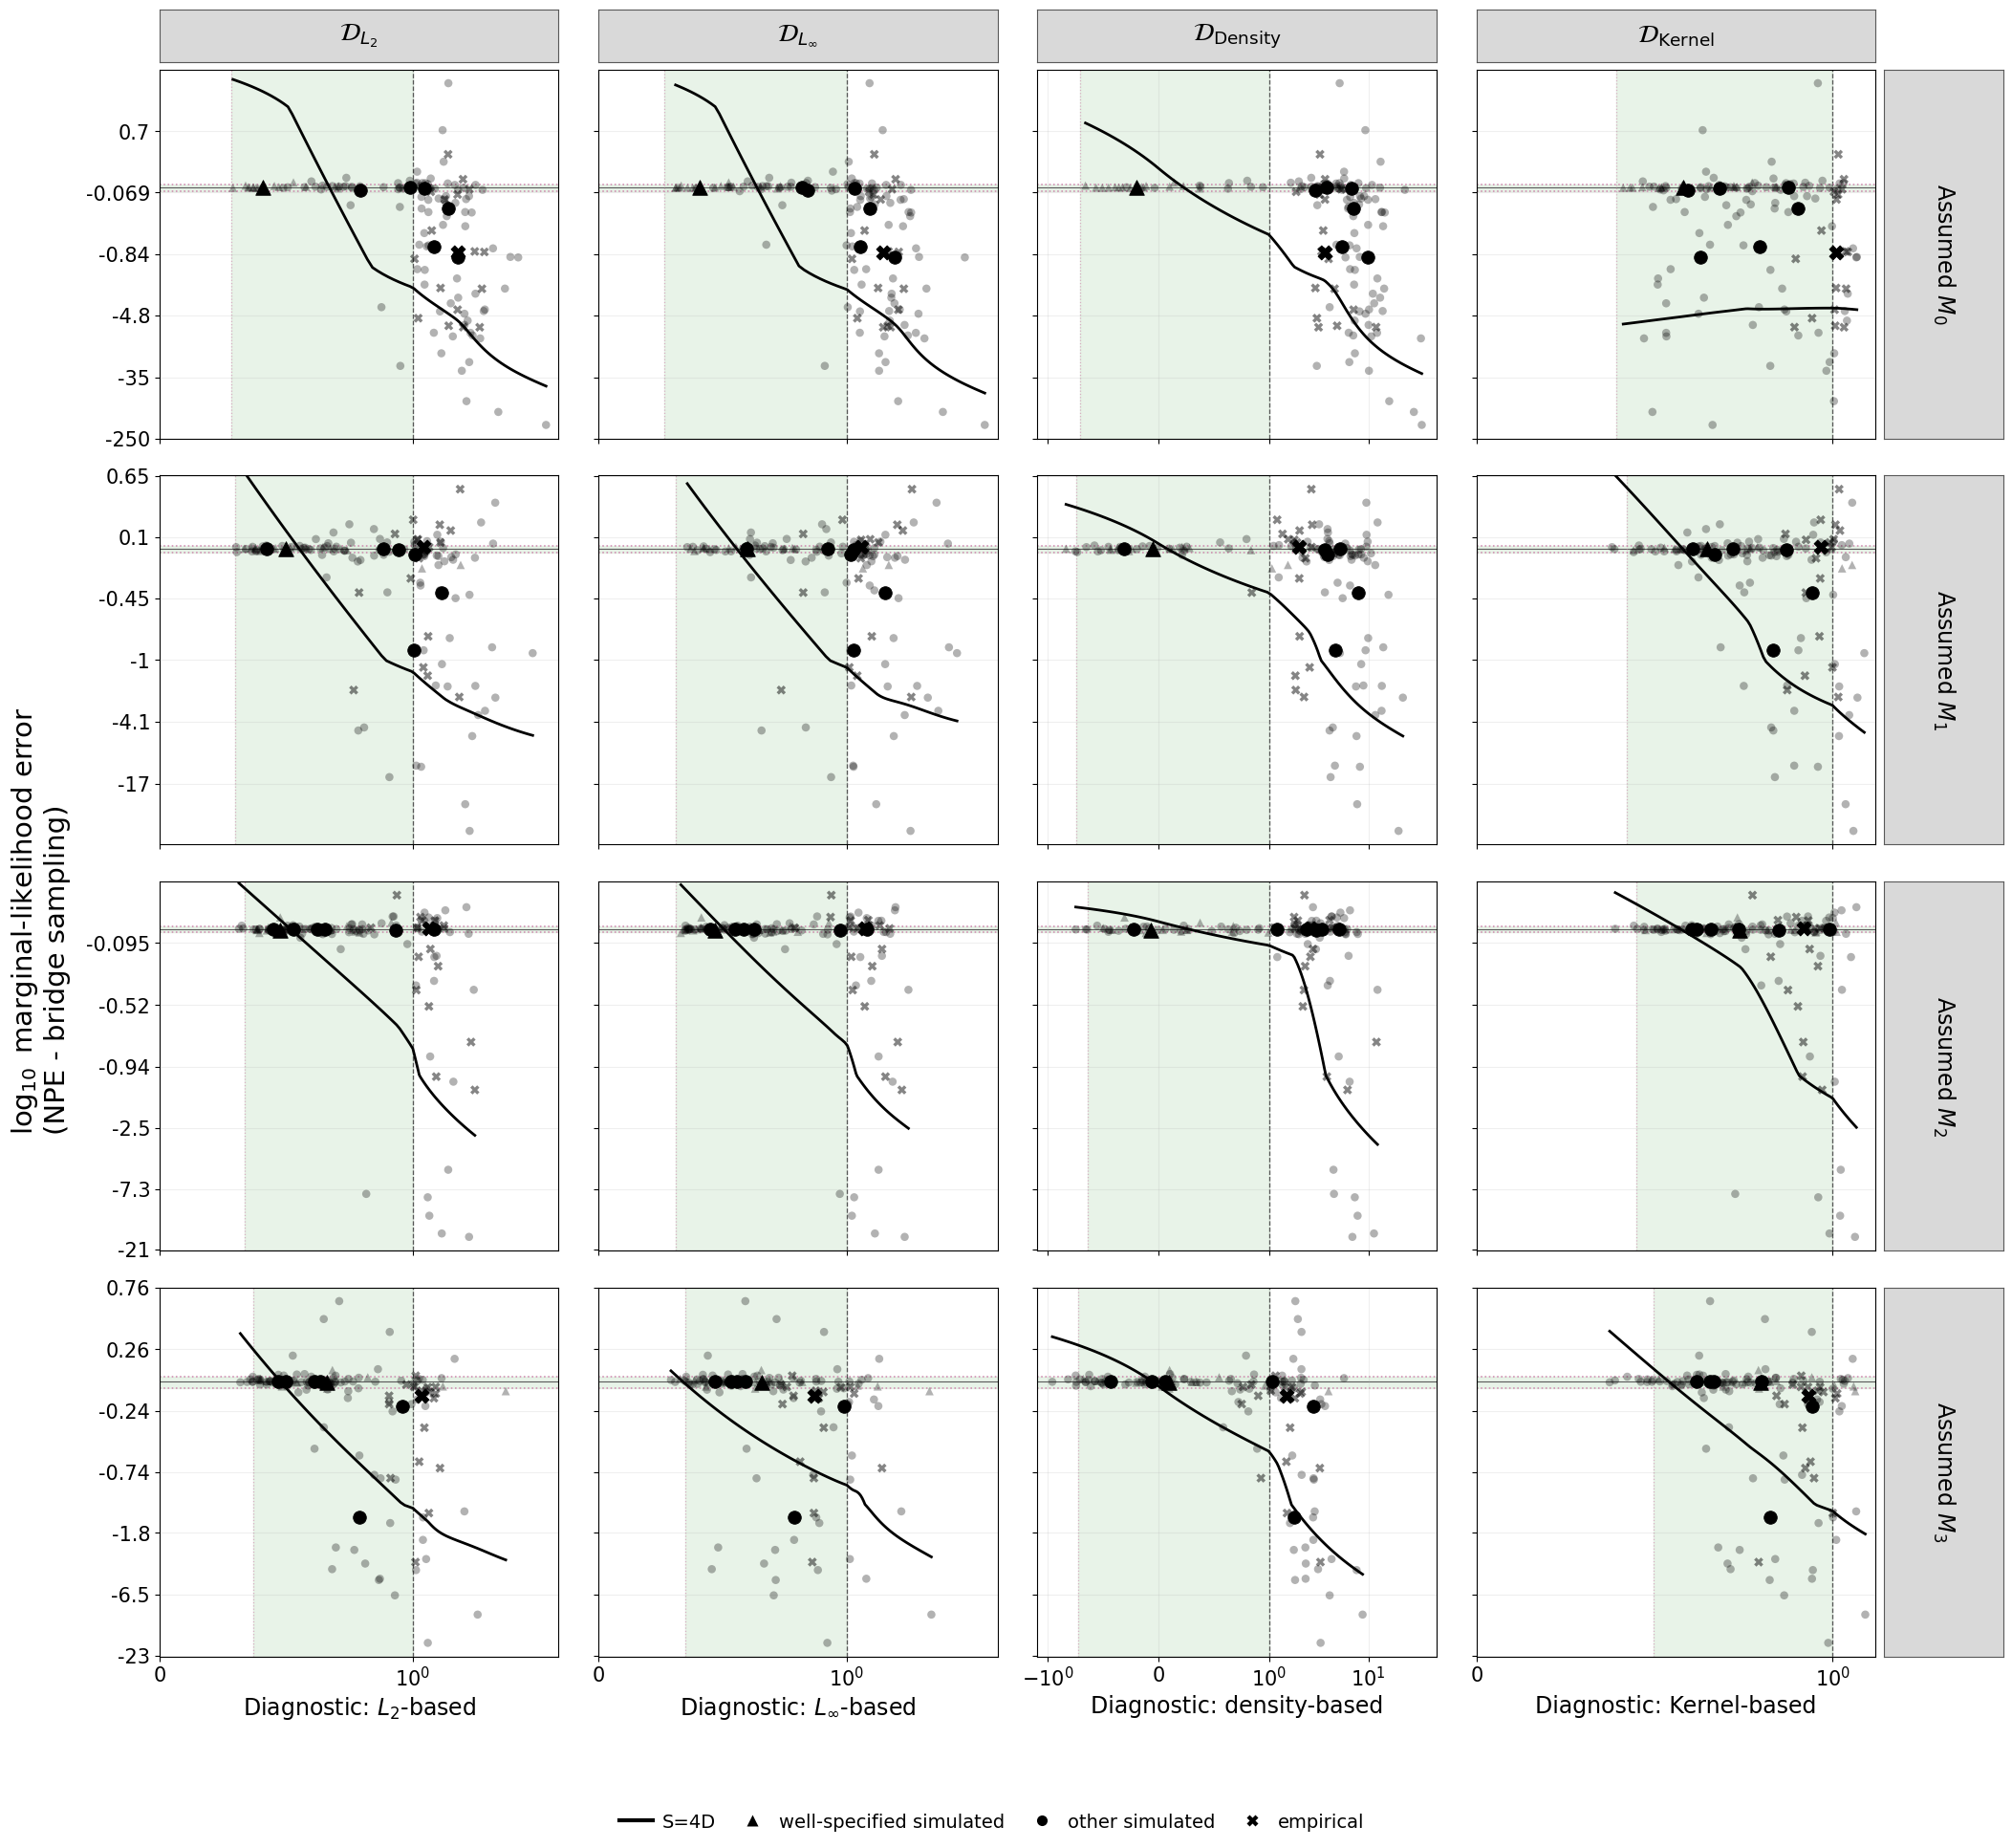

In [6]:
fig_logml, axes_logml = plot_metric_grid(
    indirect_runs,
    "logml",
    dataset_type=DATASET_TYPE,
    output=OUTPUT_ROOT / "indirect" / DATASET_TYPE / "logml_error_4x4",
    yscale="symlog",
    y_linthresh=1.0,
    loess_frac=LOESS_FRAC,
    loess_space=LOESS_SPACE,
    point_color="black",
    loess_color="black",
    dpi=DPI,
)
plt.show()


## S=4D: candidate-specific PMP error vs diagnostic score

Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/diffusion/results/plots/n384/s4D/indirect/both/pmp_error_4x4.png
Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/diffusion/results/plots/n384/s4D/indirect/both/pmp_error_4x4.pdf


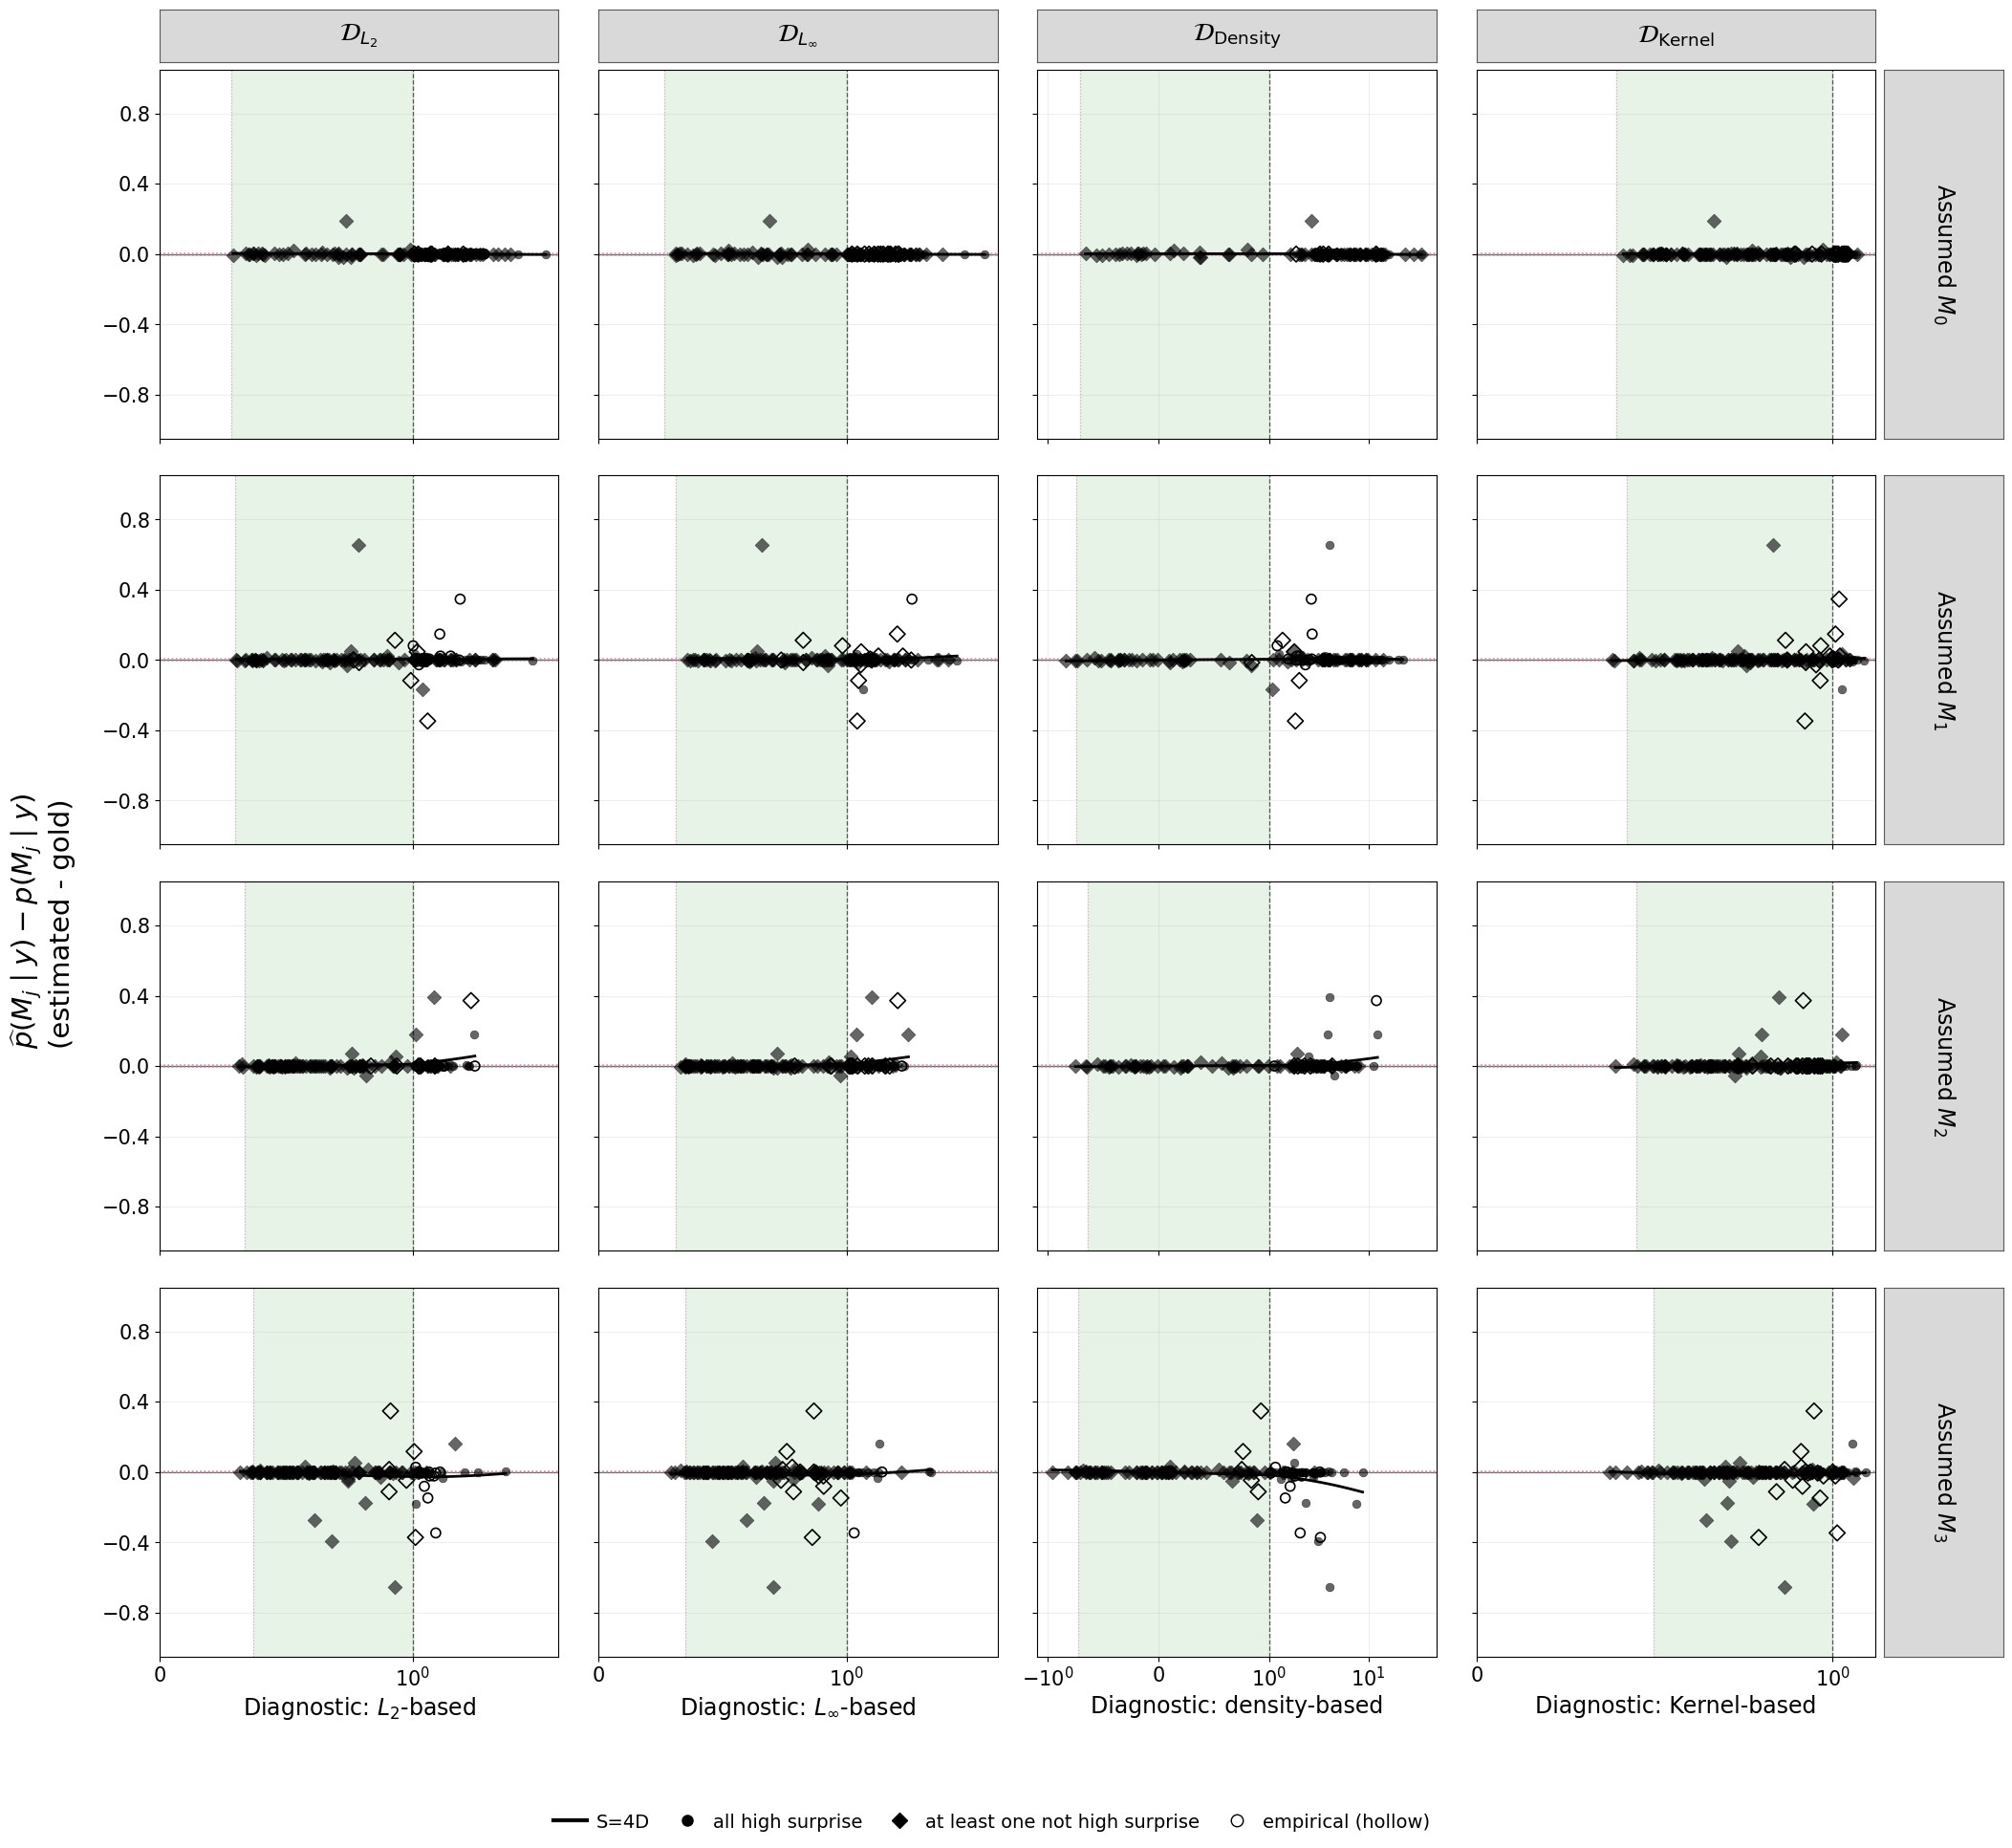

In [7]:
fig_pmp, axes_pmp = plot_metric_grid(
    indirect_runs,
    "pmp",
    dataset_type=DATASET_TYPE,
    output=OUTPUT_ROOT / "indirect" / DATASET_TYPE / "pmp_error_4x4",
    ylim=(-1.05, 1.05),
    loess_frac=LOESS_FRAC,
    loess_space=LOESS_SPACE,
    point_color="black",
    loess_color="black",
    dpi=DPI,
)
plt.show()
